<center><h1>Kim_Seonmin_HW5</h1></center>
<br>
<br>

Name: Seonmin Kim
<br>
Github Username: nimnusmik

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('../data/acute/diagnosis.data', header=None,encoding='utf-16', sep='\t', decimal=',')

df.head()

,0,1,2,3,4,5,6,7
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (a) Obtain Data

Get the Accute Inamations Data Set

In [3]:
cols = ['temp', 'nausea', 'lumbar_pain', 'urine_pushing',
        'micturition_pain', 'burning_urethra', 'inflammation', 'nephritis']

df = pd.read_csv('../data/acute/diagnosis.data', header=None, names=cols,
                 encoding='utf-16', sep='\t', decimal=',')

df.head()

,temp,nausea,lumbar_pain,urine_pushing,micturition_pain,burning_urethra,inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

In [4]:
yn_cols = cols[1:]
df[yn_cols] = df[yn_cols].replace({'yes':1, 'no':0})

df.head()

,temp,nausea,lumbar_pain,urine_pushing,micturition_pain,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [5]:
X = df[cols[:6]]
y = df['inflammation'].astype(str) + df['nephritis'].astype(str)
y.value_counts()

10    40
01    31
00    30
11    19
Name: count, dtype: int64

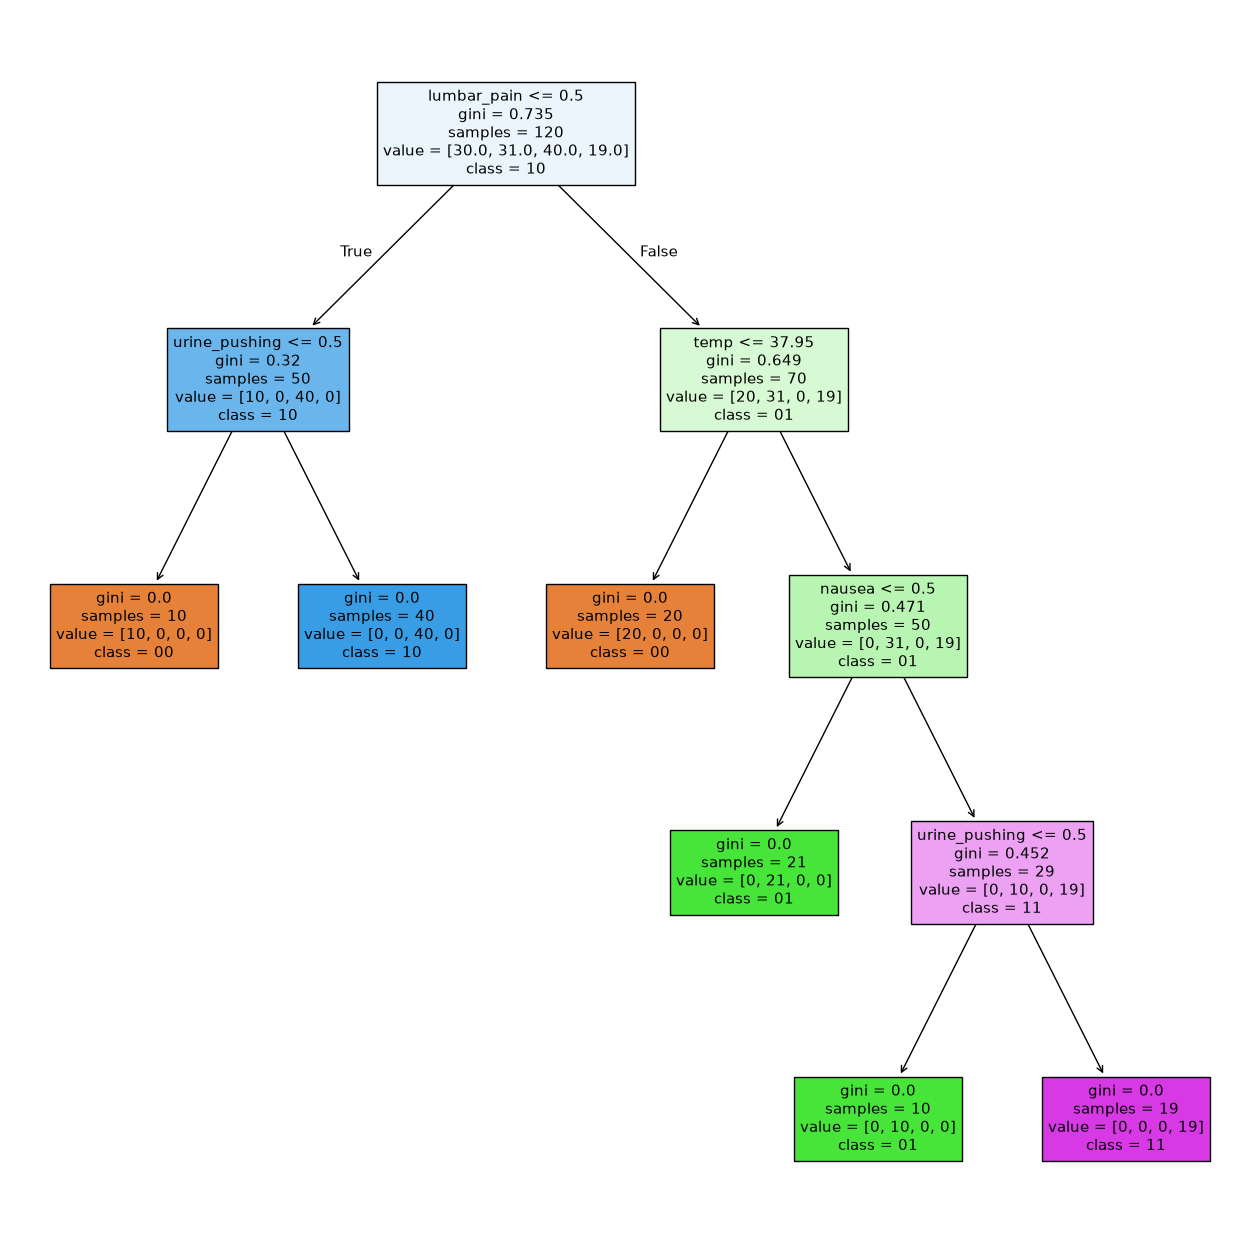

In [6]:
from sklearn.tree import DecisionTreeClassifier,plot_tree

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X,y)

plt.figure(figsize=(16,16))
plot_tree(tree, feature_names=X.columns, class_names=tree.classes_, filled = True)

plt.show()

In [7]:
tree.score(X,y)

1.0

### (c) Convert the decision rules

In [8]:
from sklearn.tree import export_text
print(export_text(tree, feature_names=list(X.columns)))

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: 00
|   |--- urine_pushing >  0.50
|   |   |--- class: 10
|--- lumbar_pain >  0.50
|   |--- temp <= 37.95
|   |   |--- class: 00
|   |--- temp >  37.95
|   |   |--- nausea <= 0.50
|   |   |   |--- class: 01
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: 01
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: 11



- IF lumbar_pain = no AND urine_pushing = no THEN inflammation = no, nephritis = no
- IF lumbar_pain = no AND urine_pushing = yes THEN inflammation = yes, nephritis = no
- IF lumbar_pain = yes AND temp <= 37.95 THEN inflammation = no, nephritis = no
- IF lumbar_pain = yes AND temp > 37.95 and nausea = no THEN inflammation = no, nephritis = yes
- IF lumbar_pain = yes AND temp > 37.95 and nausea = yes and urine_pushing = no THEN inflammation = no, nephritis = yes
- IF lumbar_pain = yes AND temp > 37.95 and  nausea = yes and urine_pushing = yes THEN inflammation = yes, nephritis = yes

### (d) Cost-complexity pruning

In [9]:
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas
alphas

array([0.        , 0.09816667, 0.13333333, 0.182     , 0.22291667])

In [10]:
for a in alphas:
    t = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    t.fit(X, y)
    print(round(a, 4), t.get_n_leaves(), t.score(X, y))


0.0 6 1.0
0.0982 4 0.8416666666666667
0.1333 3 0.7583333333333333
0.182 2 0.5916666666666667
0.2229 1 0.3333333333333333


In [11]:
small = DecisionTreeClassifier(random_state=42, ccp_alpha=alphas[1]).fit(X, y)
print(export_text(small, feature_names=list(X.columns)))

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: 00
|   |--- urine_pushing >  0.50
|   |   |--- class: 10
|--- lumbar_pain >  0.50
|   |--- temp <= 37.95
|   |   |--- class: 00
|   |--- temp >  37.95
|   |   |--- class: 01



In [12]:
from sklearn.model_selection import cross_val_score

for a in alphas:
    t = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    t.fit(X, y)
    cv = cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=a),
                         X, y, cv=5).mean()
    print(round(a, 4), t.get_n_leaves(), t.score(X, y), round(cv, 3))

0.0 6 1.0 0.958
0.0982 4 0.8416666666666667 0.775
0.1333 3 0.7583333333333333 0.717
0.182 2 0.5916666666666667 0.6
0.2229 1 0.3333333333333333 0.433


When ccp_alpha is increased above 0, the pruned tree can no longer correctly classify patients with both diseases. The unpruned tree also has the highest 5-fold CV accuracy (0.958). So I select the 6-leaf tree (ccp_alpha = 0) as the best tree model. It is the smallest tree among the pruning candidates that can still predict all four classes. With only 6 rules and at most 4 conditions per rule, it is still small enough to read by hand. Its decision rules are the same as the rules in (c).

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [13]:
with open('../data/communities/communities.data') as f:
    for _ in range(3):
        print(f.readline()[:150])

8,?,?,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0
53,?,?,Tukwilacity,1,0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0
24,?,?,Aberdeentown,1,0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0,0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01


In [14]:
names = [line.split()[1]
         for line in open('../data/communities/communities.names')
         if line.startswith('@attribute')]
len(names)

128

In [15]:
crime = pd.read_csv('../data/communities/communities.data', header=None,
                    names=names, na_values='?')

crime 

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1989,12,NaN,NaN,TempleTerracecity,10,0.01,0.40,0.10,0.87,0.12,...,0.01,0.28,0.05,NaN,NaN,NaN,NaN,0.00,NaN,0.09
1990,6,NaN,NaN,Seasidecity,10,0.05,0.96,0.46,0.28,0.83,...,0.02,0.37,0.20,NaN,NaN,NaN,NaN,0.00,NaN,0.45
1991,9,9.0,80070.0,Waterburytown,10,0.16,0.37,0.25,0.69,0.04,...,0.08,0.32,0.18,0.08,0.06,0.78,0.0,0.91,0.28,0.23
1992,25,17.0,72600.0,Walthamcity,10,0.08,0.51,0.06,0.87,0.22,...,0.03,0.38,0.33,0.02,0.02,0.79,0.0,0.22,0.18,0.19


In [16]:
crime.isna().sum().sort_values(ascending=False).head(30)

PolicReqPerOffic        1675
PolicAveOTWorked        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
LemasSwFTFieldPerPop    1675
LemasTotReqPerPop       1675
LemasSwFTFieldOps       1675
LemasSwFTPerPop         1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
LemasSwornFT            1675
PolicBudgPerPop         1675
LemasTotalReq           1675
community               1177
county                  1174
OtherPerCap                1
OwnOccMedVal               0
HousVacant                 0
PctWOFullPlumb             0
PctHousNoPhone             0
MedYrHousBuilt             0
dtype: int64

In [17]:
train = crime.iloc[:1495]
test  = crime.iloc[1495:]
train.shape, test.shape

((1495, 128), (499, 128))

### (b) Missing values

In [18]:
drop_cols = names[:5]     
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
train.shape, test.shape

((1495, 123), (499, 123))

In [19]:
from sklearn.impute import SimpleImputer

imp = SimpleImputer(strategy='mean')
train[:] = imp.fit_transform(train)
test[:]  = imp.transform(test)
train.isna().sum().sum(), test.isna().sum().sum()

(np.int64(0), np.int64(0))

All features are already normalized to [0, 1], so outliers cannot pull the mean far. So I decided to fill the missing values with the mean of the training set. One limitation is that about 84% of the values are missing in the 22 police-related features, so after imputation most values in those columns become the same constant.

### (c) Plot a correlation matrix

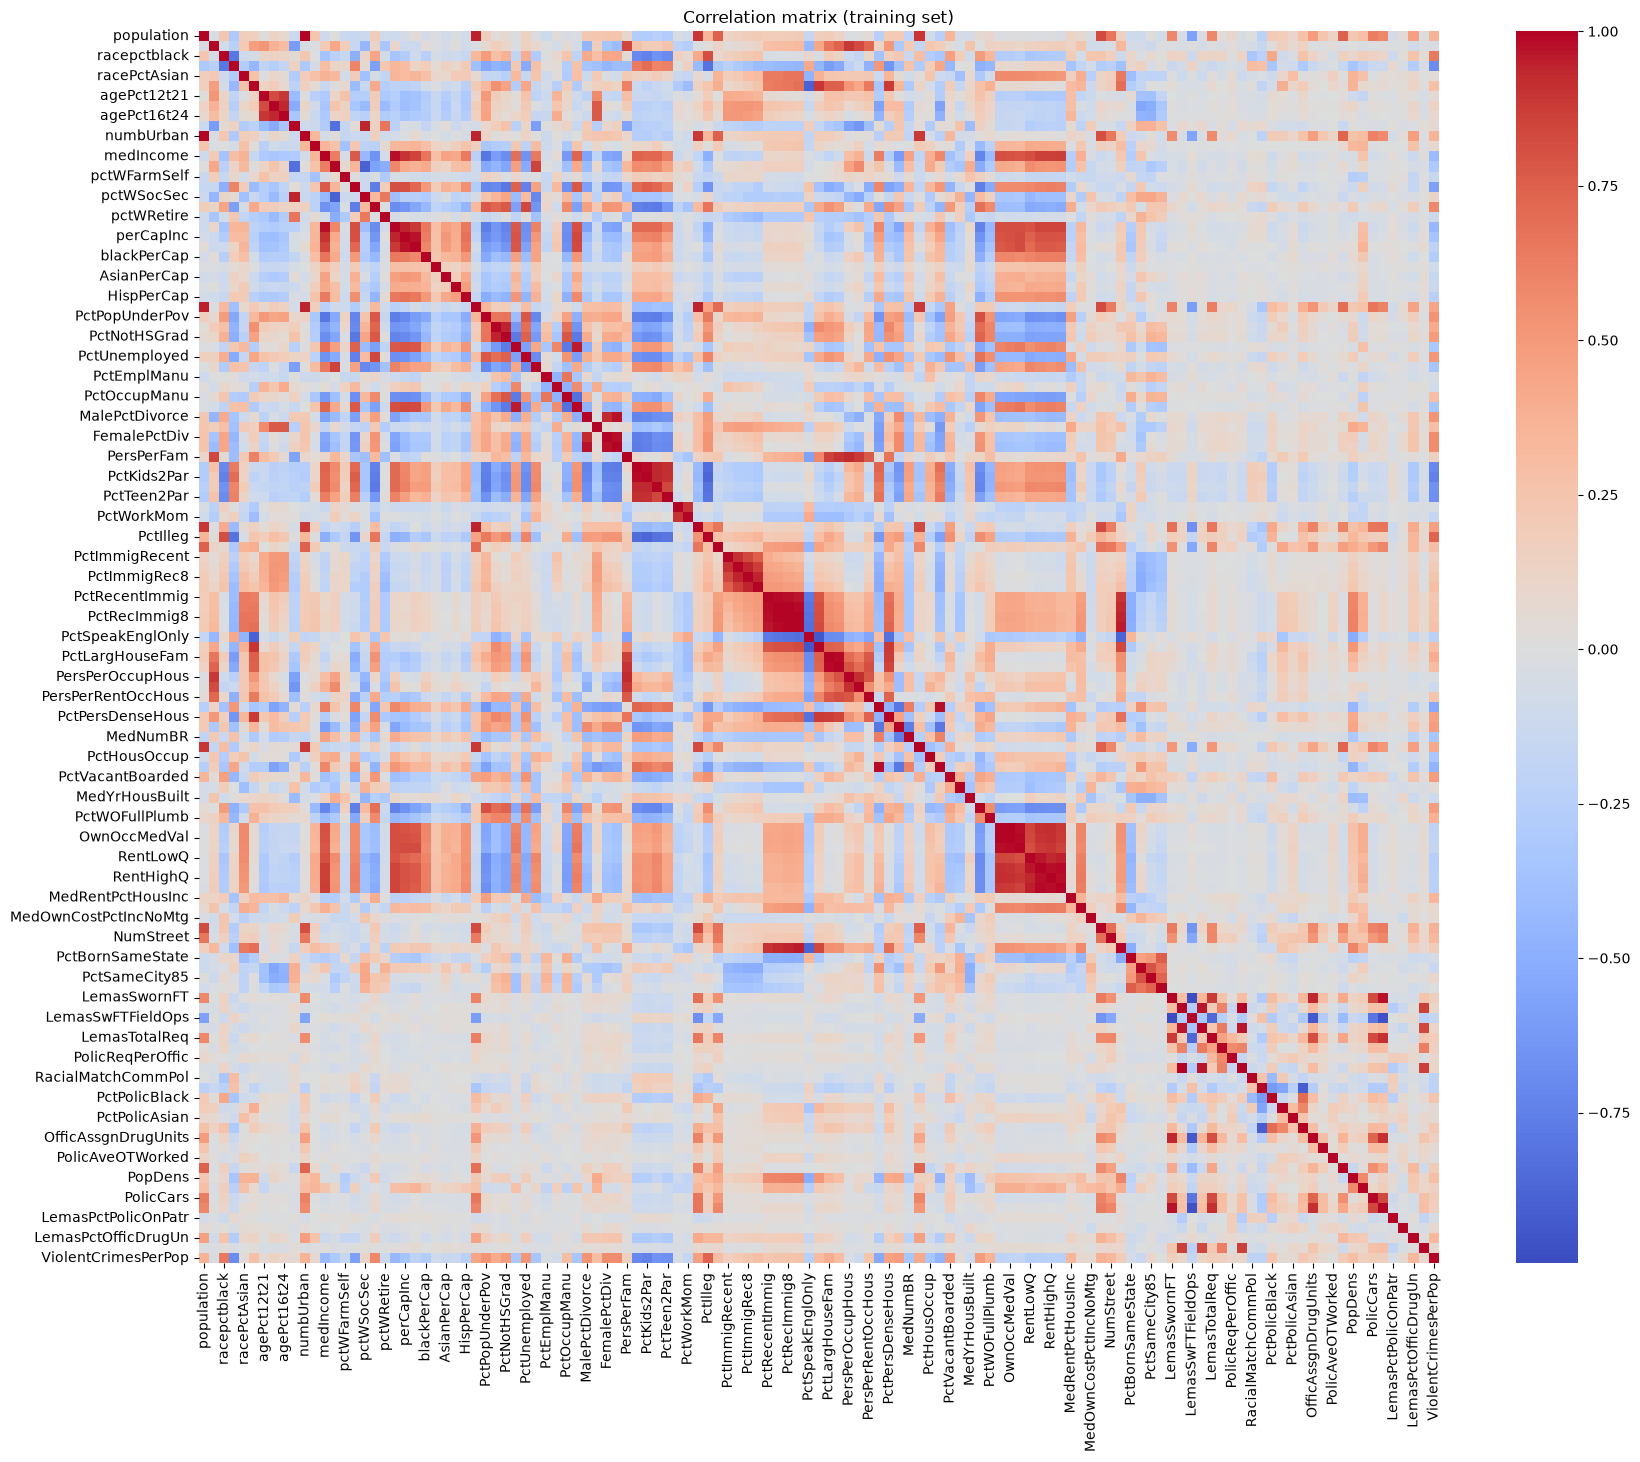

In [20]:
import seaborn as sns     

corr = train.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation matrix (training set)')
plt.show()


Several groups of features are strongly correlated, such as the housing cost features (0.84 to 0.98) and the immigration features (up to 0.98). For the target, PctKids2Par (-0.74) and PctIlleg (0.74) have the strongest correlations. This multicollinearity can make least squares unstable, which motivates ridge, LASSO, and PCR.


### (d) Calculate the Coefficient of Variation CV

In [21]:
X_cols = train.columns.drop('ViolentCrimesPerPop') 
cv = train[X_cols].std() / train[X_cols].mean()
cv.sort_values(ascending=False).head(11)

NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
LandArea               1.645408
racePctHisp            1.612091
dtype: float64

### (e) Scatter plots and box plots for highest CV features

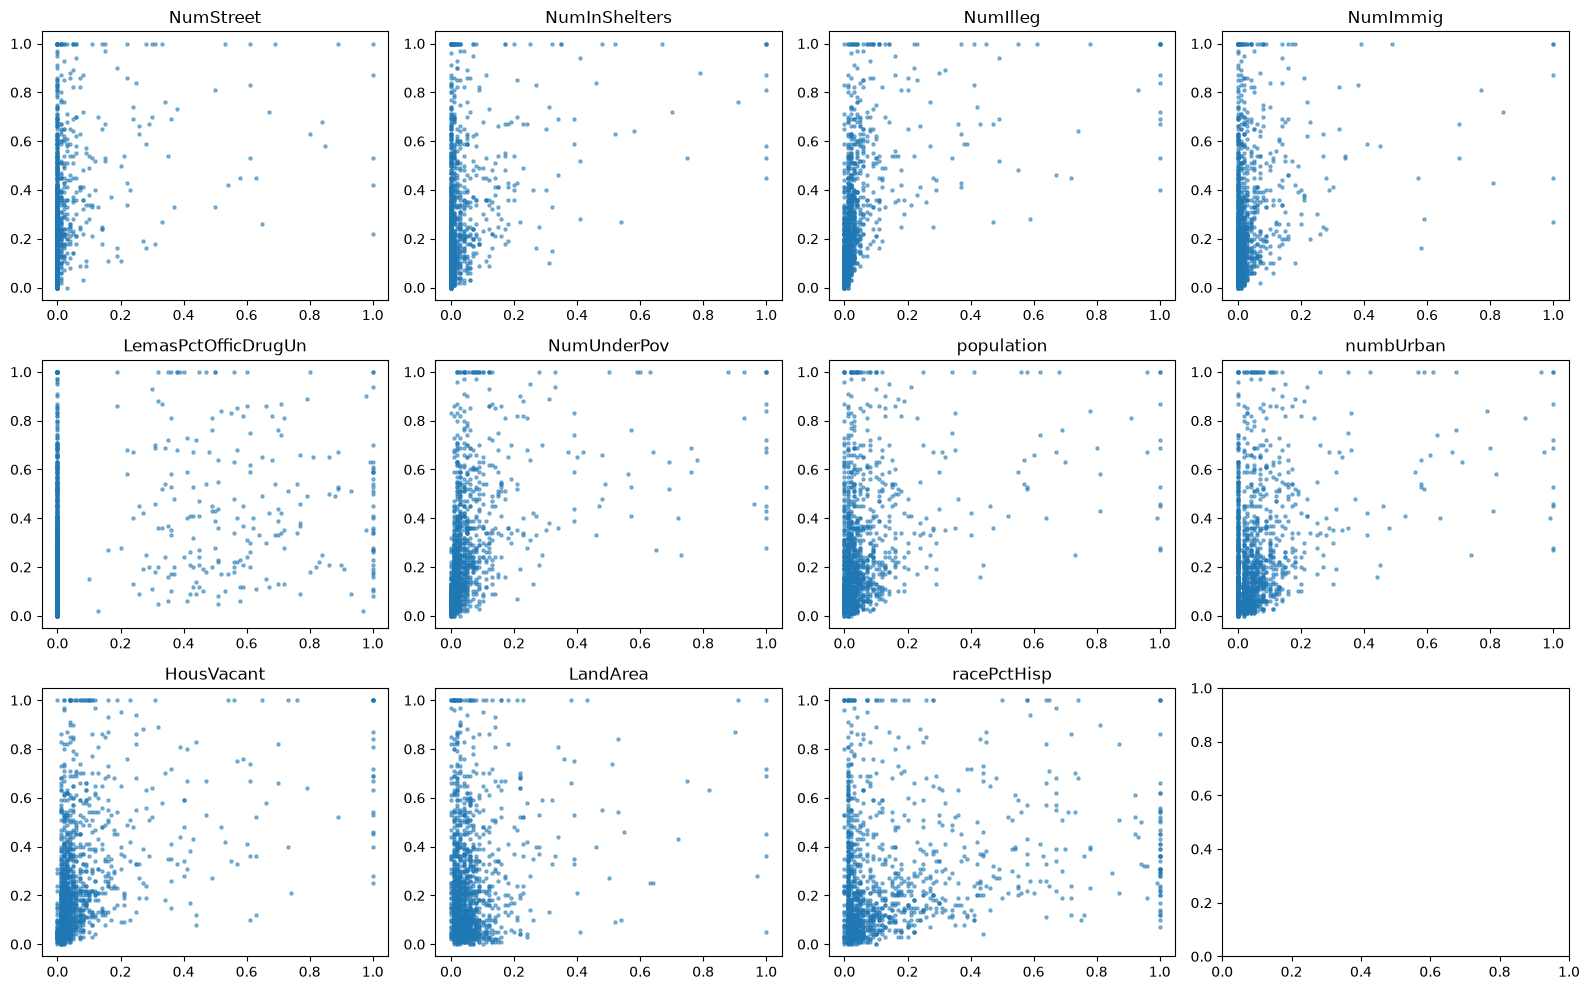

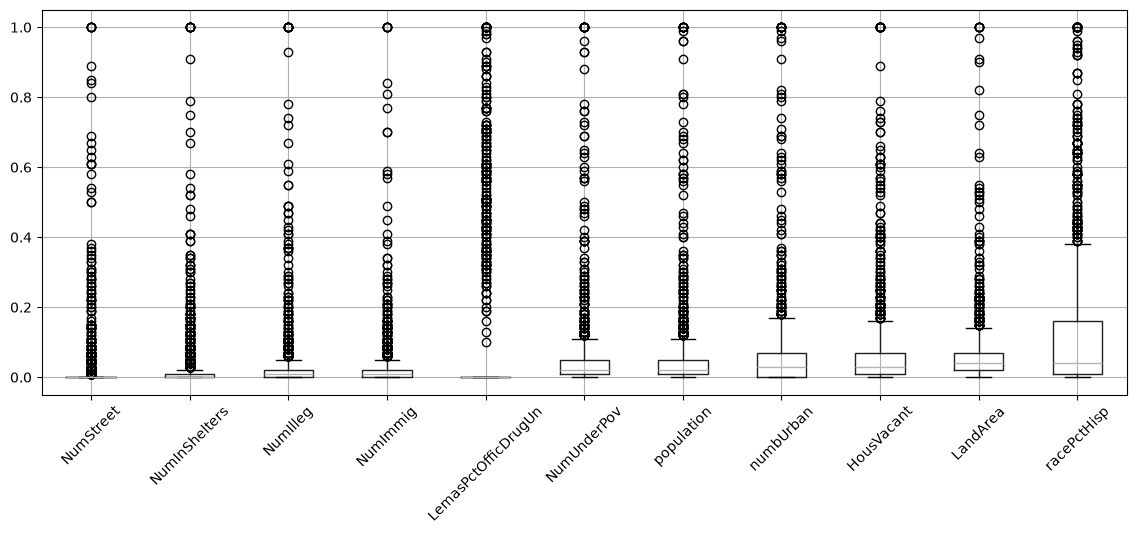

In [22]:
top11 = cv.sort_values(ascending=False).head(11).index

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, top11):
    ax.scatter(train[col], train['ViolentCrimesPerPop'], s=5, alpha=0.5)
    ax.set_title(col)
plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 5))
train[top11].boxplot()
plt.xticks(rotation=45)
plt.show()

No. Each scatter plot only shows the relationship between one feature and the target, so it gives too little information. Many points are crowded near 0, and `LemasPctOfficDrugUn` is mostly one constant value because of mean imputation. To judge significance, we need a model that uses all features together, along with statistics such as p-values.

### (f) Fit a linear model

In [23]:
target = 'ViolentCrimesPerPop'

X_train = train.drop(columns=target)
y_train = train[target]

X_test  = test.drop(columns=target)
y_test  = test[target]
X_train.shape, X_test.shape

((1495, 122), (499, 122))

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

ols = LinearRegression()
ols.fit(X_train, y_train)
mse_ols = mean_squared_error(y_test, ols.predict(X_test))
mse_ols

0.01814197113553011

The test MSE of the least squares linear model is 0.0181.

### (g) Fit a ridge regression model

In [25]:
import numpy as np
from sklearn.linear_model import RidgeCV

lambdas = np.logspace(-4, 4, 100)
ridge = RidgeCV(alphas=lambdas, cv=10)
ridge.fit(X_train, y_train)

,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",array([1.0000...00000000e+04])
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : same as 'eigen' 'svd' : use singular value decomposition of X when X is dense, fallback to 'eigen' when X is sparse 'eigen' : use eigendecomposition of X X' when n_samples <= n_features or X' X when n_features < n_samplesThe 'auto' mode is the default and is intended to pick the cheaperoption depending on the shape and sparsity of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets.This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionadded:: 0.24",False
Name,Type,Value
"alpha_ alpha_: float or ndarray of shape (n_targets,)Estimated regularization parameter, or, if ``alpha_per_target=True``,the estimated regularization parameter for each target.",float64,2.31
"best_score_ best_score_: float or ndarray of shape (n_targets,)Score of base estimator with best alpha, or, if``alpha_per_target=True``, a score for each target... versionadded:: 0.23",float64,0.6627
"coef_ coef_: ndarray of shape (n_features) or (n_targets, n_features)Weight vector(s).","ndarray[float64](122,)","[-0.01, 0.01, 0.22,..., 0.04, 0.01, 0.01]

In [26]:
mse_ridge = mean_squared_error(y_test, ridge.predict(X_test))
ridge.alpha_, mse_ridge

(np.float64(2.310129700083163), 0.017599613792452524)

 Ridge regression with lambda = 2.31 chosen by 10-fold CV gives a test MSE of 0.0176, slightly lower than least squares.

### (h) Fit a LASSO model

In [27]:
from sklearn.linear_model import LassoCV

lasso = LassoCV(cv=10, random_state=42, max_iter=50000)
lasso.fit(X_train, y_train)
mse_lasso = mean_squared_error(y_test, lasso.predict(X_test))

selected = X_train.columns[lasso.coef_ != 0]
lasso.alpha_, mse_lasso, len(selected)
print(list(selected))

['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSameState', 'PctSameCity85', 'LemasS

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lasso_std = make_pipeline(StandardScaler(),
                          LassoCV(cv=10, random_state=42, max_iter=50000))
lasso_std.fit(X_train, y_train)
mse_lasso_std = mean_squared_error(y_test, lasso_std.predict(X_test))
mse_lasso_std

0.017839043673251096

LASSO with lambda chosen by 10-fold CV gives a test MSE of 0.0178 and selects 77 of the 122 features. With standardized features, the test MSE is 0.0178 with 76 features selected, so the results are almost the same. This is because all features are already normalized to [0, 1], so they are on similar scales even before standardization.

### (i) Fit a PCR model

In [29]:
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score

cv_mse = []
Ms = range(1, 123)
for M in Ms:
    pcr = make_pipeline(PCA(n_components=M), LinearRegression())
    score = cross_val_score(pcr, X_train, y_train, cv=10,
                            scoring='neg_mean_squared_error').mean()
    cv_mse.append(-score)

best_M = Ms[int(np.argmin(cv_mse))]
pcr = make_pipeline(PCA(n_components=best_M), LinearRegression()).fit(X_train, y_train)
mse_pcr = mean_squared_error(y_test, pcr.predict(X_test))
best_M, mse_pcr

(96, 0.01847177851616755)

PCR with M = 96 principal components chosen by 10-fold CV gives a test MSE of 0.0185, slightly worse than least squares. PCA chooses components without looking at the target, so the top components are not always the most useful ones for prediction.

### (j) Fit a boosting tree

In [30]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                 random_state=42),
    param_grid={'reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10]},
    cv=5, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)

mse_xgb = mean_squared_error(y_test, grid.predict(X_test))
grid.best_params_, mse_xgb

({'reg_alpha': 0.1}, 0.01598213432412956)

The L1-penalized XGBoost model with alpha = 0.1 chosen by 5-fold CV gives a test MSE of 0.0160, the lowest among all models. Boosted trees can capture nonlinear relationships and interactions between features, which linear models cannot.

## AI Usage Disclosure

Tool: Claude Code (Claude Opus 5.5), used as a learning aid.

- **Setup and data format check:** AI set up the repository structure (folders, template copy, requirements.txt) and checked the raw data formats: `diagnosis.data` is UTF-16, tab separated, and uses a comma as the decimal mark; `communities.data` marks missing values with `?`.
- **Code:** I wrote the code myself from fill-in-the-blank hints and concept explanations given by AI. AI also explained the error messages I got (e.g., `object of type 'int' has no len()`, `NameError`).